## Environnement
Dans la barre d'outils du notebook, selectionner le noyau **mon_env_etudeCas** (Python 3.11). Ne pas choisir `~/miniforge3/bin/python` : cet interpreteur n'a pas `ipykernel` et ne peut pas lancer le notebook.

Dependances : `%pip install torch torchvision pillow` (la conversion des images n'utilise plus NumPy : plus besoin de `numpy<2`).

**Materiel.** Le noyau plantait sur le GPU du Mac (MPS). Le notebook s'execute donc sur **CPU par defaut** (`DEVICE_PREFERENCE = "cpu"`). Pour retester MPS, mettre `"auto"` ou `"mps"`; le repli automatique sur CPU des operateurs non supportes est active.

**Execution.** Executer les cellules dans l'ordre. ResNet18 et le petit CNN sont entraines dans deux cellules separees; chaque epoque sauvegarde un checkpoint dans `outputs/classification/train` (`*_latest.pth`) et la meilleure epoque selon la perte de validation (`*_best.pth`).

In [1]:
# EXPERIENCE 1 : CLASSIFICATION - CONFIGURATION ET ENVIRONNEMENT
# Comparaison : transfert d'apprentissage avec ResNet18 vs petit CNN entraine depuis zero.
# Dependances : %pip install torch torchvision pillow

import os

# Doit etre defini AVANT l'import de torch : si un operateur n'existe pas sur MPS,
# PyTorch bascule sur le CPU au lieu de planter.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import copy
import csv
import gc
import random
from pathlib import Path

import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models

# Les identifiants 0, 1 et 2 viennent de small_dataset/data.yaml.
CLASS_NAMES = ["glioma", "meningioma", "pituitary"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
IMAGE_SIZE = 224
BATCH_SIZE = 8
EPOCHS_CLASSIFICATION = 10
SEED = 42
PRETRAINED = True  # False = ResNet18 aleatoire (utile hors ligne, sans telechargement des poids)

# "cpu" par defaut : le noyau plantait sur MPS (Mac). Passer a "auto" ou "mps" pour retester.
DEVICE_PREFERENCE = "cpu"  # "cpu", "auto", "mps" ou "cuda"

DATASET_ROOT = Path("small_dataset")
CLASSIFICATION_TRAIN_DIR = Path("outputs/classification/train")
CLASSIFICATION_EVAL_DIR = Path("outputs/classification/evaluation")
CLASSIFICATION_TRAIN_DIR.mkdir(parents=True, exist_ok=True)
CLASSIFICATION_EVAL_DIR.mkdir(parents=True, exist_ok=True)

# Normalisation ImageNet partagee par les deux modeles (creee une seule fois).
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def set_seed(seed):
    """Rendre les entrainements reproductibles (ordre des batches, init des poids)."""
    random.seed(seed)
    torch.manual_seed(seed)


def select_device(preference):
    if preference == "cuda" and torch.cuda.is_available():
        return torch.device("cuda")
    if preference == "mps" and torch.backends.mps.is_available():
        return torch.device("mps")
    if preference == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        if torch.backends.mps.is_available():
            return torch.device("mps")
    return torch.device("cpu")


def free_device_memory():
    """Liberer la memoire de l'accelerateur entre deux entrainements."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()


set_seed(SEED)
DEVICE = select_device(DEVICE_PREFERENCE)
print(f"PyTorch {torch.__version__} | materiel : {DEVICE} | batch={BATCH_SIZE} | graine={SEED}")

PyTorch 2.2.2 | materiel : cpu | batch=8 | graine=42


In [2]:
# DONNEES : une image = une classe (annotation YOLO), avec rapport des images ecartees.
class TumorClassificationDataset(Dataset):
    """Associe chaque image a la classe unique de son annotation YOLO."""

    def __init__(self, split):
        self.samples = []
        self.skipped = {"sans_label": 0, "label_vide": 0, "classes_multiples": 0, "classe_inconnue": 0}
        images_dir = DATASET_ROOT / split / "images"
        labels_dir = DATASET_ROOT / split / "labels"

        for image_path in sorted(images_dir.iterdir()):
            if not image_path.is_file() or image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue
            label_path = labels_dir / f"{image_path.stem}.txt"
            if not label_path.is_file():
                self.skipped["sans_label"] += 1
                continue

            class_ids = {
                int(fields[0])
                for line in label_path.read_text(encoding="utf-8").splitlines()
                if (fields := line.split()) and fields[0].isdigit()
            }
            if not class_ids:
                self.skipped["label_vide"] += 1
            elif len(class_ids) > 1:
                self.skipped["classes_multiples"] += 1
            else:
                class_id = next(iter(class_ids))
                if 0 <= class_id < len(CLASS_NAMES):
                    self.samples.append((image_path, class_id))
                else:
                    self.skipped["classe_inconnue"] += 1

        counts = [sum(1 for _, c in self.samples if c == i) for i in range(len(CLASS_NAMES))]
        ignored = {k: v for k, v in self.skipped.items() if v}
        print(
            f"{split}: {len(self.samples)} images classees "
            f"({dict(zip(CLASS_NAMES, counts))})"
            + (f" | ecartees : {ignored}" if ignored else "")
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, class_id = self.samples[index]
        # Fermer le fichier apres lecture (evite l'accumulation de descripteurs ouverts).
        with Image.open(image_path) as image:
            image = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
            raw_bytes = bytearray(image.tobytes())
        # Conversion sans NumPy : evite tout conflit de version NumPy 1.x / 2.x avec PyTorch.
        pixels = torch.frombuffer(raw_bytes, dtype=torch.uint8)
        pixels = pixels.view(IMAGE_SIZE, IMAGE_SIZE, 3).permute(2, 0, 1).float() / 255.0
        return (pixels - IMAGENET_MEAN) / IMAGENET_STD, class_id


# Seul train sert a mettre a jour les poids; valid choisit la meilleure epoque; test = evaluation finale.
classification_datasets = {
    split: TumorClassificationDataset(split) for split in ("train", "valid", "test")
}
if any(len(dataset) == 0 for dataset in classification_datasets.values()):
    raise ValueError("Au moins un split ne contient aucune image classee.")

classification_loaders = {
    split: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=(split == "train"),
        num_workers=0,
        generator=torch.Generator().manual_seed(SEED) if split == "train" else None,
    )
    for split, dataset in classification_datasets.items()
}

train: 300 images classees ({'glioma': 100, 'meningioma': 100, 'pituitary': 100})
valid: 150 images classees ({'glioma': 50, 'meningioma': 50, 'pituitary': 50})
test: 150 images classees ({'glioma': 50, 'meningioma': 50, 'pituitary': 50})


In [3]:
# MODELES, EVALUATION ET BOUCLE D'ENTRAINEMENT


# ResNet18 avec poids ImageNet; seule la derniere couche est remplacee (tout le reseau reste entrainable).
def build_resnet18_classifier():
    weights = models.ResNet18_Weights.DEFAULT if PRETRAINED else None
    try:
        model = models.resnet18(weights=weights)
    except Exception as error:  # telechargement impossible (hors ligne, proxy...)
        raise RuntimeError(
            "Impossible de charger les poids ImageNet de ResNet18. Verifier la connexion ou "
            "mettre PRETRAINED = False pour un reseau aleatoire (la comparaison perd son sens)."
        ) from error
    model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
    return model


# CNN compact initialise aleatoirement, sans poids pre-entraines.
def build_small_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
        nn.Linear(128, len(CLASS_NAMES)),
    )


# Perte, exactitude et rappel par classe sur un split, sans modifier le modele.
@torch.no_grad()
def evaluate_classifier(model, split, loss_function):
    model.eval()
    total_loss = 0.0
    total = 0
    confusion = torch.zeros(len(CLASS_NAMES), len(CLASS_NAMES), dtype=torch.long)  # [vrai, predit]
    for images, labels in classification_loaders[split]:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        total_loss += loss_function(logits, labels).item() * labels.size(0)
        total += labels.size(0)
        for true_label, predicted in zip(labels.cpu().tolist(), logits.argmax(dim=1).cpu().tolist()):
            confusion[true_label, predicted] += 1
    accuracy = confusion.diag().sum().item() / total
    per_class_recall = [
        confusion[i, i].item() / max(confusion[i].sum().item(), 1) for i in range(len(CLASS_NAMES))
    ]
    return total_loss / total, accuracy, per_class_recall, confusion.tolist()


def write_history_csv(history, path):
    with Path(path).open("w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=history[0].keys())
        writer.writeheader()
        writer.writerows(history)


# Meme boucle et meme nombre d'epoques pour comparer; le taux d'apprentissage depend du modele :
# 1e-3 est trop fort pour affiner des poids pre-entraines (il detruit les caracteristiques apprises).
def train_classifier(model, model_name, slug, learning_rate):
    set_seed(SEED)
    model = model.to(DEVICE)
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    best_valid_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(EPOCHS_CLASSIFICATION):
        model.train()
        total_loss = 0.0
        total = 0
        for images, labels in classification_loaders["train"]:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_function(model(images), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            total += labels.size(0)

        train_loss = total_loss / total
        valid_loss, valid_accuracy, _, _ = evaluate_classifier(model, "valid", loss_function)
        history.append(
            {
                "epoch": epoch + 1,
                "train_loss": train_loss,
                "valid_loss": valid_loss,
                "valid_accuracy": valid_accuracy,
            }
        )
        print(
            f"{model_name} | epoque {epoch + 1}/{EPOCHS_CLASSIFICATION} | "
            f"perte train {train_loss:.4f} | perte valid {valid_loss:.4f} | "
            f"exactitude valid {valid_accuracy:.2%}"
        )

        # Garder la meilleure epoque selon la perte de validation (copie sur CPU).
        if valid_loss < best_valid_loss:
            best_valid_loss, best_epoch = valid_loss, epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(
                {
                    "epoch": best_epoch,
                    "model_state_dict": best_state,
                    "history": history,
                    "class_names": CLASS_NAMES,
                },
                CLASSIFICATION_TRAIN_DIR / f"{slug}_best.pth",
            )

        # Dernier etat complet pour reprendre apres un arret du noyau (poids copies sur CPU).
        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "optimizer_state_dict": optimizer.state_dict(),
                "history": history,
                "class_names": CLASS_NAMES,
            },
            CLASSIFICATION_TRAIN_DIR / f"{slug}_latest.pth",
        )
        write_history_csv(history, CLASSIFICATION_TRAIN_DIR / f"{slug}_history.csv")

    # Evaluer sur test le modele de la meilleure epoque (choisie sur valid, jamais sur test).
    model.load_state_dict(best_state)
    test_loss, test_accuracy, per_class_recall, confusion = evaluate_classifier(model, "test", loss_function)
    print(
        f"{model_name} | meilleure epoque {best_epoch} | perte test {test_loss:.4f} | "
        f"exactitude test {test_accuracy:.2%}"
    )
    print("  rappel par classe :", {n: f"{r:.2%}" for n, r in zip(CLASS_NAMES, per_class_recall)})
    print("  matrice de confusion (lignes = vrai, colonnes = predit) :", confusion)

    # Rendre le modele sur CPU et liberer l'accelerateur avant l'entrainement suivant.
    model = model.cpu()
    del optimizer
    free_device_memory()
    return model, history, {
        "best_epoch": best_epoch,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "per_class_recall": per_class_recall,
    }

In [4]:
# ENTRAINEMENT 1/2 : ResNet18 (transfert d'apprentissage).
resnet18_model, resnet18_history, resnet18_test = train_classifier(
    build_resnet18_classifier(), "ResNet18 transfert", "resnet18_transfer", learning_rate=1e-4
)

ResNet18 transfert | epoque 1/10 | perte train 0.5596 | perte valid 0.6273 | exactitude valid 76.67%
ResNet18 transfert | epoque 2/10 | perte train 0.1332 | perte valid 0.3267 | exactitude valid 87.33%
ResNet18 transfert | epoque 3/10 | perte train 0.1111 | perte valid 0.3314 | exactitude valid 89.33%
ResNet18 transfert | epoque 4/10 | perte train 0.0662 | perte valid 0.3791 | exactitude valid 86.00%
ResNet18 transfert | epoque 5/10 | perte train 0.1011 | perte valid 0.4942 | exactitude valid 86.00%
ResNet18 transfert | epoque 6/10 | perte train 0.0438 | perte valid 0.3439 | exactitude valid 88.00%
ResNet18 transfert | epoque 7/10 | perte train 0.0511 | perte valid 0.3305 | exactitude valid 88.67%
ResNet18 transfert | epoque 8/10 | perte train 0.0345 | perte valid 0.4516 | exactitude valid 85.33%
ResNet18 transfert | epoque 9/10 | perte train 0.0830 | perte valid 0.2917 | exactitude valid 86.67%
ResNet18 transfert | epoque 10/10 | perte train 0.0680 | perte valid 0.3654 | exactitude va

In [5]:
# ENTRAINEMENT 2/2 : petit CNN depuis zero (cellule separee : un plantage ici ne perd pas ResNet18).
small_cnn_model, small_cnn_history, small_cnn_test = train_classifier(
    build_small_cnn(), "Petit CNN from scratch", "small_cnn_from_scratch", learning_rate=1e-3
)

Petit CNN from scratch | epoque 1/10 | perte train 0.8987 | perte valid 0.8913 | exactitude valid 64.67%
Petit CNN from scratch | epoque 2/10 | perte train 0.8023 | perte valid 1.1476 | exactitude valid 45.33%
Petit CNN from scratch | epoque 3/10 | perte train 0.7264 | perte valid 0.7831 | exactitude valid 70.67%
Petit CNN from scratch | epoque 4/10 | perte train 0.7471 | perte valid 0.9527 | exactitude valid 55.33%
Petit CNN from scratch | epoque 5/10 | perte train 0.7698 | perte valid 0.7337 | exactitude valid 68.67%
Petit CNN from scratch | epoque 6/10 | perte train 0.7263 | perte valid 0.7797 | exactitude valid 66.00%
Petit CNN from scratch | epoque 7/10 | perte train 0.6622 | perte valid 0.7385 | exactitude valid 65.33%
Petit CNN from scratch | epoque 8/10 | perte train 0.6799 | perte valid 0.6759 | exactitude valid 76.67%
Petit CNN from scratch | epoque 9/10 | perte train 0.6462 | perte valid 2.0109 | exactitude valid 39.33%
Petit CNN from scratch | epoque 10/10 | perte train 0.6

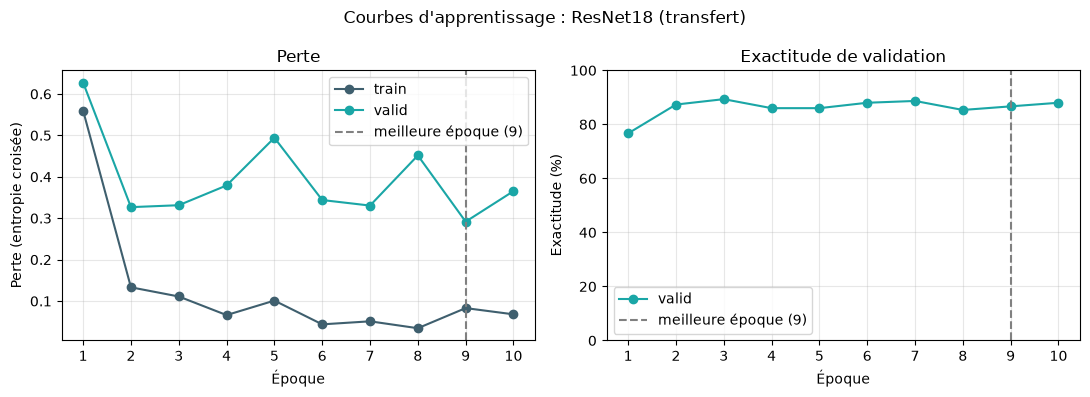

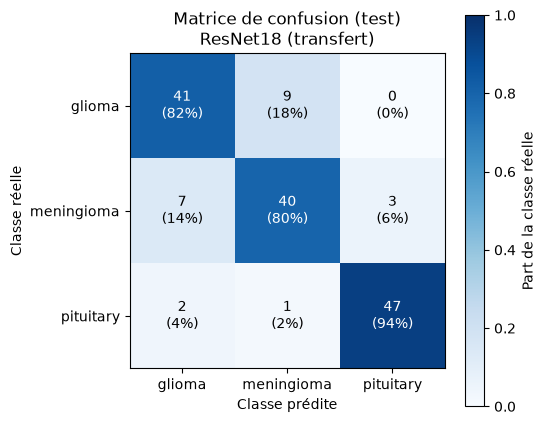

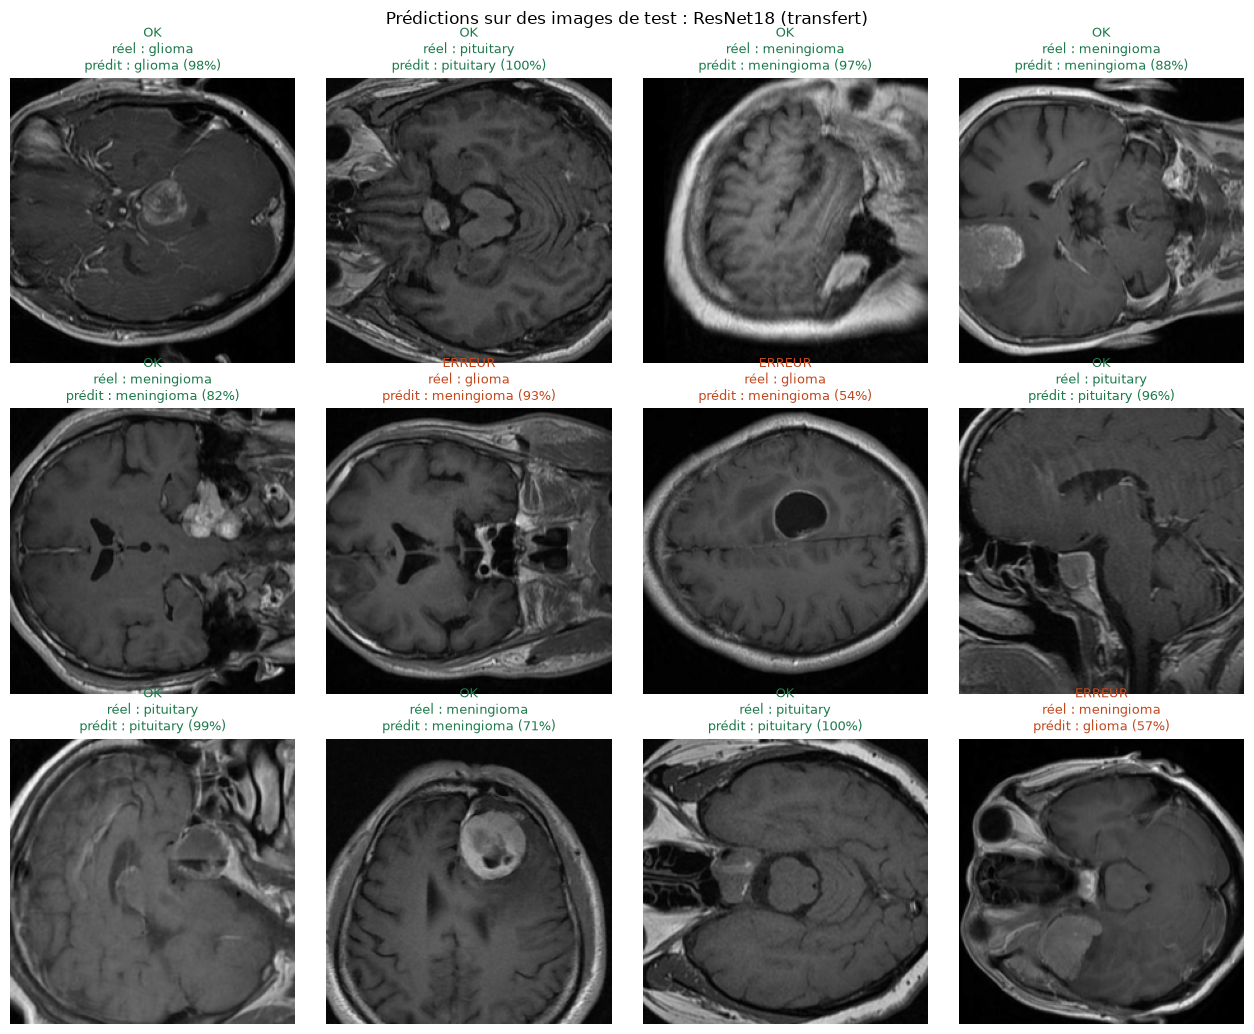

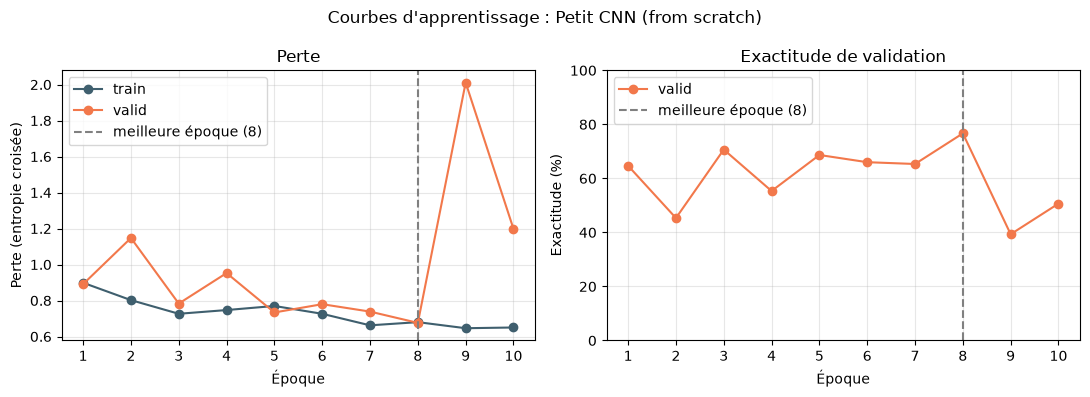

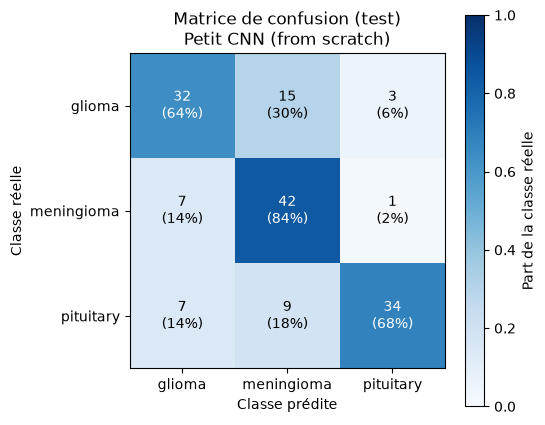

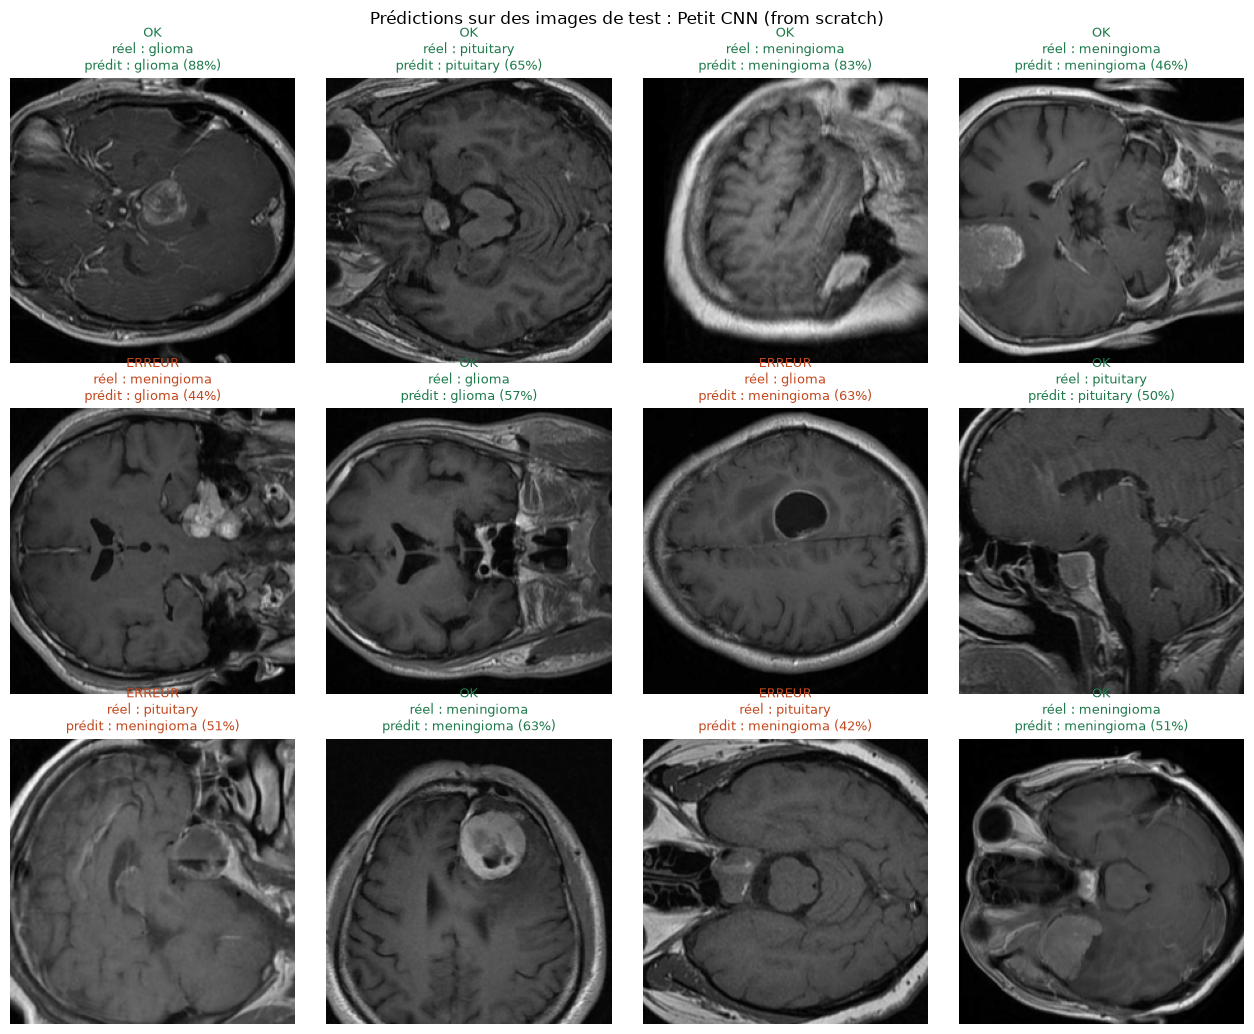

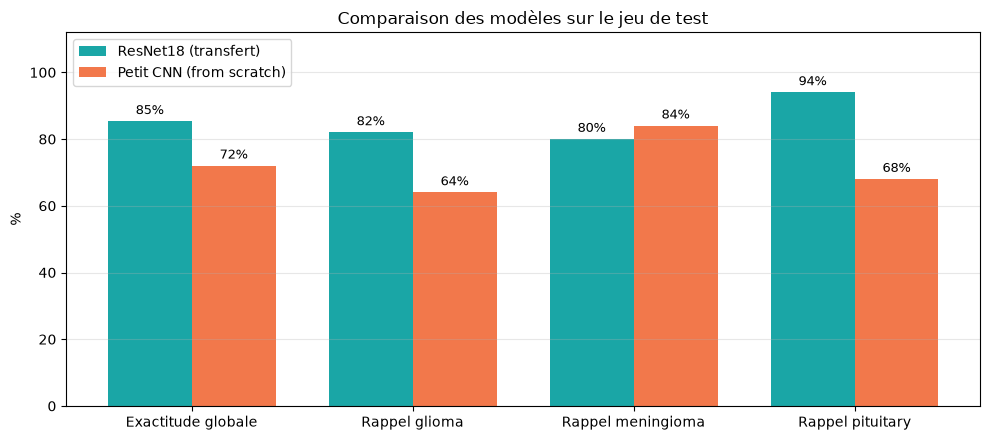

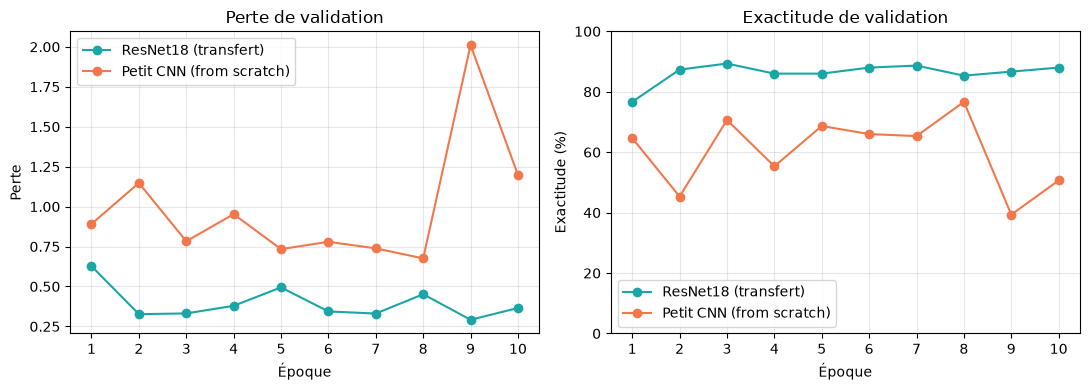

Modeles et historiques classification : outputs/classification/train
Evaluation classification : outputs/classification/evaluation/test_metrics.csv
Figures (8) dans : outputs/classification/evaluation/figures
  - resnet18_transfer_learning_curves.png
  - resnet18_transfer_confusion_matrix.png
  - resnet18_transfer_test_predictions.png
  - small_cnn_from_scratch_learning_curves.png
  - small_cnn_from_scratch_confusion_matrix.png
  - small_cnn_from_scratch_test_predictions.png
  - comparison_test_metrics.png
  - comparison_validation_curves.png


In [7]:
# SAUVEGARDE + FIGURES : poids finaux (meilleure epoque), metriques de test et images de resultats.
# Dependance : %pip install matplotlib
import math

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

FIGURES_DIR = CLASSIFICATION_EVAL_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MODEL_LABELS = {
    "resnet18_transfer": "ResNet18 (transfert)",
    "small_cnn_from_scratch": "Petit CNN (from scratch)",
}
MODEL_COLORS = {"resnet18_transfer": "#1AA6A6", "small_cnn_from_scratch": "#F2784B"}

classification_models = {
    "resnet18_transfer": (resnet18_model, resnet18_history, resnet18_test),
    "small_cnn_from_scratch": (small_cnn_model, small_cnn_history, small_cnn_test),
}

# ---------------------------------------------------------------- 1. Poids, historiques, tableau CSV
classification_results = []
for model_name, (model, history, test_metrics) in classification_models.items():
    model_path = CLASSIFICATION_TRAIN_DIR / f"{model_name}.pth"
    torch.save({"model_state_dict": model.state_dict(), "class_names": CLASS_NAMES}, model_path)
    write_history_csv(history, CLASSIFICATION_TRAIN_DIR / f"{model_name}_history.csv")

    row = {
        "model": model_name,
        "best_epoch": test_metrics["best_epoch"],
        "test_loss": test_metrics["test_loss"],
        "test_accuracy": test_metrics["test_accuracy"],
    }
    for class_name, recall in zip(CLASS_NAMES, test_metrics["per_class_recall"]):
        row[f"recall_{class_name}"] = recall
    row["checkpoint"] = str(model_path)
    classification_results.append(row)

with (CLASSIFICATION_EVAL_DIR / "test_metrics.csv").open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=classification_results[0].keys())
    writer.writeheader()
    writer.writerows(classification_results)


# ---------------------------------------------------------------- 2. Fonctions de figures
saved_figures = []


def save_figure(fig, file_name):
    """Enregistrer la figure en PNG (150 dpi), l'afficher dans le notebook, puis la fermer."""
    path = FIGURES_DIR / file_name
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    saved_figures.append(path)


def plot_learning_curves(model_name, history, best_epoch):
    """Perte (train / valid) et exactitude de validation par epoque, meilleure epoque marquee."""
    epochs = [h["epoch"] for h in history]
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
    ax_loss.plot(epochs, [h["train_loss"] for h in history], marker="o", label="train", color="#3F5F6E")
    ax_loss.plot(epochs, [h["valid_loss"] for h in history], marker="o", label="valid",
                 color=MODEL_COLORS[model_name])
    ax_loss.set(title="Perte", xlabel="Époque", ylabel="Perte (entropie croisée)")
    ax_acc.plot(epochs, [h["valid_accuracy"] * 100 for h in history], marker="o",
                color=MODEL_COLORS[model_name], label="valid")
    ax_acc.set(title="Exactitude de validation", xlabel="Époque", ylabel="Exactitude (%)")
    ax_acc.set_ylim(0, 100)
    for ax in (ax_loss, ax_acc):
        ax.axvline(best_epoch, color="gray", linestyle="--", label=f"meilleure époque ({best_epoch})")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(f"Courbes d'apprentissage : {MODEL_LABELS[model_name]}")
    save_figure(fig, f"{model_name}_learning_curves.png")


def plot_confusion_matrix(model_name, confusion):
    """Matrice de confusion sur test : effectifs et pourcentage par classe reelle."""
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    totals = [max(sum(line), 1) for line in confusion]
    shares = [[value / totals[i] for value in line] for i, line in enumerate(confusion)]
    image = ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    for i, line in enumerate(confusion):
        for j, value in enumerate(line):
            ax.text(j, i, f"{value}\n({shares[i][j]:.0%})", ha="center", va="center",
                    color="white" if shares[i][j] > 0.5 else "black")
    ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES)
    ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
    ax.set(xlabel="Classe prédite", ylabel="Classe réelle",
           title=f"Matrice de confusion (test)\n{MODEL_LABELS[model_name]}")
    fig.colorbar(image, ax=ax, label="Part de la classe réelle")
    save_figure(fig, f"{model_name}_confusion_matrix.png")


@torch.no_grad()
def plot_prediction_samples(model_name, model, n_images=12, columns=4):
    """Images de test tirees au hasard (graine fixe) : classe reelle, classe predite, confiance."""
    test_dataset = classification_datasets["test"]
    chosen = random.Random(SEED).sample(range(len(test_dataset)), min(n_images, len(test_dataset)))
    rows = math.ceil(len(chosen) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(3.2 * columns, 3.5 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, index in zip(axes.ravel(), chosen):
        tensor, true_id = test_dataset[index]
        probabilities = torch.softmax(model(tensor.unsqueeze(0).to(DEVICE)), dim=1)[0].cpu()
        predicted_id = int(probabilities.argmax())
        # Retirer la normalisation ImageNet; .tolist() evite toute dependance a .numpy().
        shown = (tensor * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).permute(1, 2, 0)
        ax.imshow(shown.tolist())
        correct = predicted_id == true_id
        ax.set_title(
            f"{'OK' if correct else 'ERREUR'}\nréel : {CLASS_NAMES[true_id]}\n"
            f"prédit : {CLASS_NAMES[predicted_id]} ({probabilities[predicted_id]:.0%})",
            fontsize=9, color="#1F7A4C" if correct else "#C2491F",
        )
    fig.suptitle(f"Prédictions sur des images de test : {MODEL_LABELS[model_name]}")
    save_figure(fig, f"{model_name}_test_predictions.png")


# ---------------------------------------------------------------- 3. Figures par modele
loss_function = nn.CrossEntropyLoss()
for model_name, (model, history, test_metrics) in classification_models.items():
    plot_learning_curves(model_name, history, test_metrics["best_epoch"])

    # Les modeles sont rendus sur CPU : les remettre sur l'appareil de calcul pour l'inference.
    model = model.to(DEVICE)
    _, _, _, confusion = evaluate_classifier(model, "test", loss_function)
    plot_confusion_matrix(model_name, confusion)
    plot_prediction_samples(model_name, model)
    model.cpu()
    free_device_memory()


# ---------------------------------------------------------------- 4. Figures de comparaison
# 4a. Metriques de test : exactitude globale et rappel par classe.
metric_names = ["Exactitude globale"] + [f"Rappel {name}" for name in CLASS_NAMES]
fig, ax = plt.subplots(figsize=(10, 4.5))
bar_width = 0.38
for offset, (model_name, (_, _, test_metrics)) in zip((-bar_width / 2, bar_width / 2), classification_models.items()):
    values = [test_metrics["test_accuracy"]] + list(test_metrics["per_class_recall"])
    bars = ax.bar([i + offset for i in range(len(values))], [v * 100 for v in values], bar_width,
                  label=MODEL_LABELS[model_name], color=MODEL_COLORS[model_name])
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in values], padding=3, fontsize=9)
ax.set_xticks(range(len(metric_names)), metric_names)
ax.set(ylabel="%", ylim=(0, 112), title="Comparaison des modèles sur le jeu de test")
ax.grid(axis="y", alpha=0.3)
ax.legend()
save_figure(fig, "comparison_test_metrics.png")

# 4b. Courbes de validation superposees.
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
for model_name, (_, history, _) in classification_models.items():
    epochs = [h["epoch"] for h in history]
    ax_loss.plot(epochs, [h["valid_loss"] for h in history], marker="o",
                 color=MODEL_COLORS[model_name], label=MODEL_LABELS[model_name])
    ax_acc.plot(epochs, [h["valid_accuracy"] * 100 for h in history], marker="o",
                color=MODEL_COLORS[model_name], label=MODEL_LABELS[model_name])
ax_loss.set(title="Perte de validation", xlabel="Époque", ylabel="Perte")
ax_acc.set(title="Exactitude de validation", xlabel="Époque", ylabel="Exactitude (%)", ylim=(0, 100))
for ax in (ax_loss, ax_acc):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend()
save_figure(fig, "comparison_validation_curves.png")

print(f"Modeles et historiques classification : {CLASSIFICATION_TRAIN_DIR}")
print(f"Evaluation classification : {CLASSIFICATION_EVAL_DIR / 'test_metrics.csv'}")
print(f"Figures ({len(saved_figures)}) dans : {FIGURES_DIR}")
for figure_path in saved_figures:
    print(f"  - {figure_path.name}")